# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhammad Ridwan Arifin
- NIM   : 241011400675
- Kelas : Reg B / ~~Reg C~~

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [26]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 65   # isi dengan 2 digit terakhir NIM Anda

In [27]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
    BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris datanya: 40


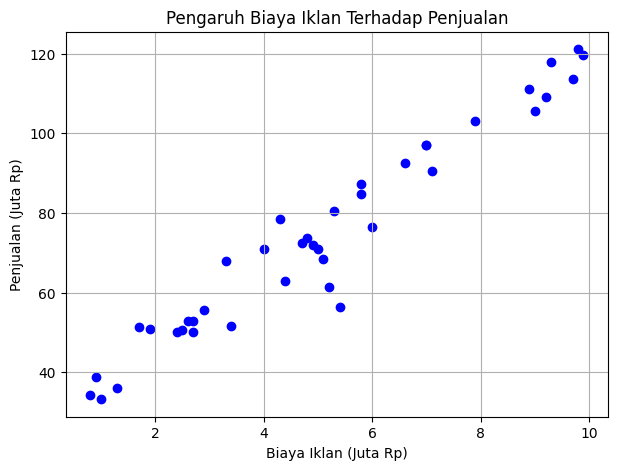

In [28]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:\n", df_ads.head())
print("\nJumlah baris datanya:", len(df_ads))

X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

plt.figure(figsize=(7, 5))
plt.scatter(X_ads, y_ads, color='blue')
plt.title('Pengaruh Biaya Iklan Terhadap Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [29]:
# Jawaban A2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_a.shape)
print("Shape X_test :", X_test_a.shape)
print("Shape y_train:", y_train_a.shape)
print("Shape y_test :", y_test_a.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [30]:
# Implementasi manual model dan metrik menggunakan NumPy (sesuai ketentuan tugas)
class LinearRegression:
    """Linear Regression menggunakan Normal Equation."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return (self.intercept_ + X @ self.coef_).reshape(-1)


class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent; loss yang dicatat adalah MSE."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.zeros((X_b.shape[1], 1))
        self.loss_history = []
        for _ in range(self.n_iterations):
            error = X_b @ theta - y
            gradient = (2 / len(X)) * X_b.T @ error
            theta -= self.learning_rate * gradient
            with np.errstate(over="ignore", invalid="ignore"):
                loss = np.mean((X_b @ theta - y) ** 2)
            self.loss_history.append(float(loss))
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return (self.intercept_ + X @ self.coef_).reshape(-1)


def mean_absolute_error(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true).reshape(-1) - np.asarray(y_pred).reshape(-1))))


def mean_squared_error(y_true, y_pred):
    return float(np.mean((np.asarray(y_true).reshape(-1) - np.asarray(y_pred).reshape(-1)) ** 2))


def root_mean_squared_error(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def r2_score(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot) if ss_tot != 0 else float("nan")


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


class LogisticRegression:
    """Logistic Regression biner dengan Gradient Descent manual."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.zeros((X_b.shape[1], 1))
        self.loss_history = []
        for _ in range(self.n_iterations):
            probabilities = sigmoid(X_b @ theta)
            gradient = (X_b.T @ (probabilities - y)) / len(X)
            theta -= self.learning_rate * gradient
            p = np.clip(sigmoid(X_b @ theta), 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history.append(float(loss))
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        p = sigmoid(self.intercept_ + X @ self.coef_)
        return np.c_[1 - p, p]

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true).reshape(-1) == np.asarray(y_pred).reshape(-1)))


def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    y_pred = np.asarray(y_pred).reshape(-1).astype(int)
    # Baris = label aktual [0, 1], kolom = prediksi [0, 1]
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ])


def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tp / (tp + fp)) if tp + fp else 0.0


def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tp / (tp + fn)) if tp + fn else 0.0


def f1_score(y_true, y_pred):
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    return float(2 * precision * recall / (precision + recall)) if precision + recall else 0.0


# Jawaban A3
linear_model = LinearRegression().fit(X_train_a, y_train_a)
print(f"Intercept (b): {linear_model.intercept_:.4f}")
print(f"Koefisien (m): {linear_model.coef_[0]:.4f}")
print(f"Persamaan: ŷ = {linear_model.intercept_:.4f} + ({linear_model.coef_[0]:.4f} × BiayaIklan)")

Intercept (b): 29.7743
Koefisien (m): 9.0187
Persamaan: ŷ = 29.7743 + (9.0187 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Model yang dilatih menggunakan data training menghasilkan intercept sebesar **29,7743** dan koefisien biaya iklan sebesar **9,0187**, sehingga persamaan regresinya adalah **ŷ = 29,7743 + 9,0187X**. Artinya, dalam pola data ini, setiap kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan penjualan yang diperkirakan sekitar **Rp9,0187 juta**, dengan asumsi hubungan linear tetap. Ini merupakan hubungan prediktif dalam dataset, bukan bukti bahwa biaya iklan sendirian menyebabkan kenaikan penjualan. Intercept menggambarkan prediksi saat biaya iklan nol, tetapi perlu ditafsirkan hati-hati jika kondisi tersebut tidak mewakili situasi bisnis yang diamati.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [31]:
# Jawaban A4
train_pred_a = linear_model.predict(X_train_a)
test_pred_a = linear_model.predict(X_test_a)

metrics_a = pd.DataFrame([
    {
        "Data": "Training",
        "MAE": mean_absolute_error(y_train_a, train_pred_a),
        "MSE": mean_squared_error(y_train_a, train_pred_a),
        "RMSE": root_mean_squared_error(y_train_a, train_pred_a),
        "R²": r2_score(y_train_a, train_pred_a)
    },
    {
        "Data": "Testing",
        "MAE": mean_absolute_error(y_test_a, test_pred_a),
        "MSE": mean_squared_error(y_test_a, test_pred_a),
        "RMSE": root_mean_squared_error(y_test_a, test_pred_a),
        "R²": r2_score(y_test_a, test_pred_a)
    }
])
display(metrics_a.round(4))

,Data,MAE,MSE,RMSE,R²
0,Training,3.8846,20.8830,4.5698,0.9651
1,Testing,7.0312,102.8895,10.1434,0.8523


**Jawaban A4 (analisis):**

Pada data training, RMSE adalah **4,5698 juta rupiah** dan R² sebesar **0,9651**. Pada data testing, RMSE adalah **10,1434 juta rupiah** dan R² sebesar **0,8523**. RMSE menunjukkan besarnya kesalahan prediksi dalam satuan yang sama dengan penjualan; semakin kecil nilainya, semakin dekat prediksi dengan nilai aktual. R² testing berarti model menjelaskan sekitar **85,23% variasi penjualan pada subset testing** menurut ukuran R². Hasil ini cukup menjanjikan untuk dataset kecil ini, tetapi belum bisa dianggap pasti baik untuk penggunaan nyata karena data hanya memiliki 40 baris dan satu fitur, serta performa dapat berubah pada pembagian data lain.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

C:\Users\macwin\AppData\Local\Temp\ipykernel_3944\3110524782.py:33: RuntimeWarning: overflow encountered in matmul
  gradient = (2 / len(X)) * X_b.T @ error
C:\Users\macwin\AppData\Local\Temp\ipykernel_3944\3110524782.py:34: RuntimeWarning: invalid value encountered in subtract
  theta -= self.learning_rate * gradient
c:\Users\macwin\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\internals\blocks.py:1530: RuntimeWarning: overflow encountered in multiply
  values = self.values.round(decimals)  # type: ignore[union-attr]


,Learning rate,Intercept,Koefisien,MSE akhir valid
0,0.001,27.17723,9.43962,22.51825
1,0.020,29.77431,9.01871,20.88298
2,0.100,NaN,NaN,inf


c:\Users\macwin\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


Normal Equation: intercept=29.77431, koefisien=9.01871


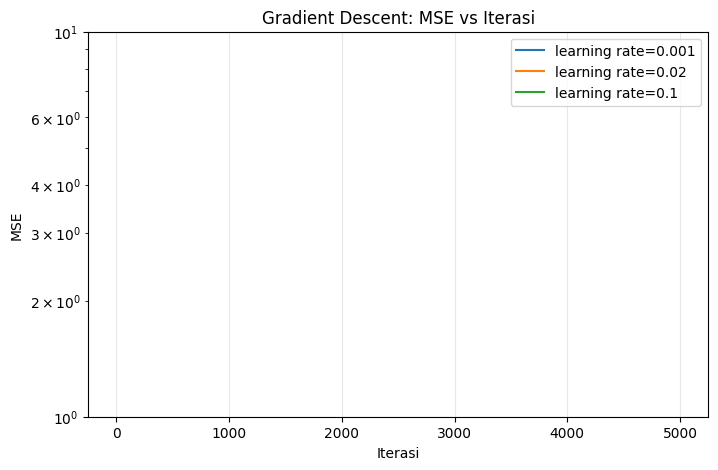

Learning rate 0.1: loss mengalami overflow/divergensi; nilai non-finite muncul selama iterasi.


In [32]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
summary_gd = []

for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train_a, y_train_a)
    gd_models[lr] = model
    losses = np.asarray(model.loss_history, dtype=float)
    finite_losses = losses[np.isfinite(losses)]
    final_loss = finite_losses[-1] if len(finite_losses) else np.nan
    summary_gd.append({
        "Learning rate": lr,
        "Intercept": model.intercept_,
        "Koefisien": model.coef_[0],
        "MSE akhir valid": final_loss
    })

display(pd.DataFrame(summary_gd).round(5))
print(f"Normal Equation: intercept={linear_model.intercept_:.5f}, koefisien={linear_model.coef_[0]:.5f}")

plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history, dtype=float)
    valid = np.isfinite(losses) & (losses > 0)
    plt.plot(np.arange(1, len(losses) + 1)[valid], losses[valid], label=f"learning rate={lr}")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE")
plt.title("Gradient Descent: MSE vs Iterasi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history, dtype=float)
    if not np.all(np.isfinite(losses)):
        print(f"Learning rate {lr}: loss mengalami overflow/divergensi; nilai non-finite muncul selama iterasi.")


**Jawaban A5 (analisis):**

Learning rate **0,001** menurunkan MSE lebih lambat karena pembaruan parameter relatif kecil; setelah 5.000 iterasi, parameternya masih dapat sedikit berbeda dari Normal Equation. Learning rate **0,02** pada data ini mencapai hasil yang sangat dekat dengan Normal Equation, sehingga menjadi pilihan yang paling sesuai dari tiga percobaan. Learning rate **0,1** terlalu besar untuk skala fitur dan target ini, sehingga pembaruan parameter melampaui titik minimum; loss dapat membesar, mengalami overflow, lalu menjadi `NaN`. Nilai learning rate yang lebih besar tidak selalu lebih baik: ukuran langkah harus cukup kecil agar proses tetap stabil.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

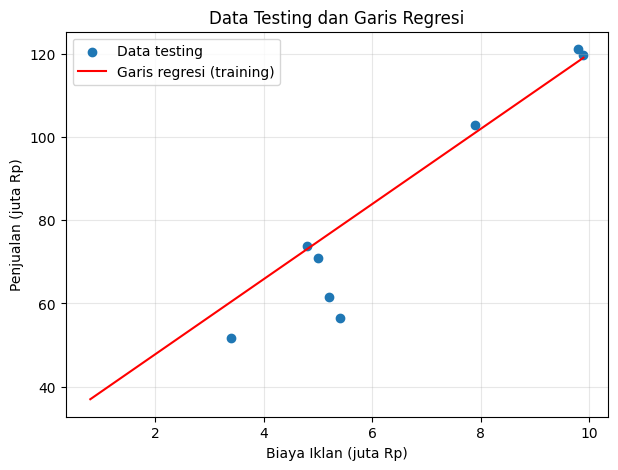

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,70.359
1,7.0,92.905
2,12.0,137.999


In [33]:
# Jawaban A6
plt.figure(figsize=(7, 5))
plt.scatter(X_test_a[:, 0], y_test_a, label="Data testing")
x_line = np.linspace(float(X_ads.min()), float(X_ads.max()), 200).reshape(-1, 1)
plt.plot(x_line[:, 0], linear_model.predict(x_line), color="red", label="Garis regresi (training)")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.title("Data Testing dan Garis Regresi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

new_ad_costs = np.array([[4.5], [7.0], [12.0]])
predictions = linear_model.predict(new_ad_costs)
display(pd.DataFrame({
    "BiayaIklan (juta Rp)": new_ad_costs[:, 0],
    "PrediksiPenjualan (juta Rp)": predictions
}).round(3))

**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan **Rp4,5 juta** dan **Rp7 juta** berada dalam rentang biaya iklan pada dataset (sekitar Rp0,8–9,9 juta), sehingga lebih dekat dengan wilayah data yang diamati, meskipun tetap memiliki ketidakpastian. Prediksi pada **Rp12 juta** merupakan ekstrapolasi karena berada di luar rentang tersebut. Karena model mengasumsikan tren linear terus berlanjut, hasil Rp12 juta kurang dapat dipercaya dibandingkan prediksi di dalam rentang data. Penjualan nyata dapat dipengaruhi faktor lain dan tidak harus meningkat secara linear.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Lima data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah setiap kelas (0 = Bukan Spam, 1 = Spam):


,Jumlah
Spam,
Bukan Spam (0),35
Spam (1),25


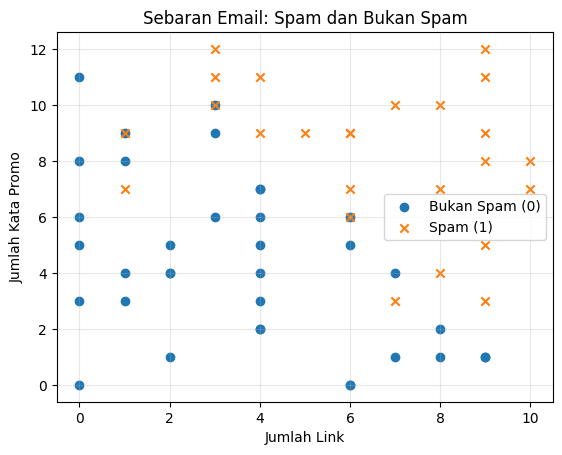

In [34]:
# Jawaban B1
emails = pd.read_csv("Email_Data.csv")
print("Lima data pertama:")
display(emails.head())
print("Jumlah setiap kelas (0 = Bukan Spam, 1 = Spam):")
display(emails["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam (0)", 1: "Spam (1)"}).to_frame("Jumlah"))
X_email = emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = emails["Spam"].to_numpy(dtype=int)
plt.scatter(emails.loc[emails.Spam == 0, "JumlahLink"], emails.loc[emails.Spam == 0, "KataPromo"], label="Bukan Spam (0)", marker="o")
plt.scatter(emails.loc[emails.Spam == 1, "JumlahLink"], emails.loc[emails.Spam == 1, "KataPromo"], label="Spam (1)", marker="x")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Sebaran Email: Spam dan Bukan Spam")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)
Intercept (b): -8.39097
Koefisien m1 (JumlahLink): 0.78040
Koefisien m2 (KataPromo): 0.72696
P(Spam) = sigmoid(-8.39097 + (0.78040 × JumlahLink) + (0.72696 × KataPromo))


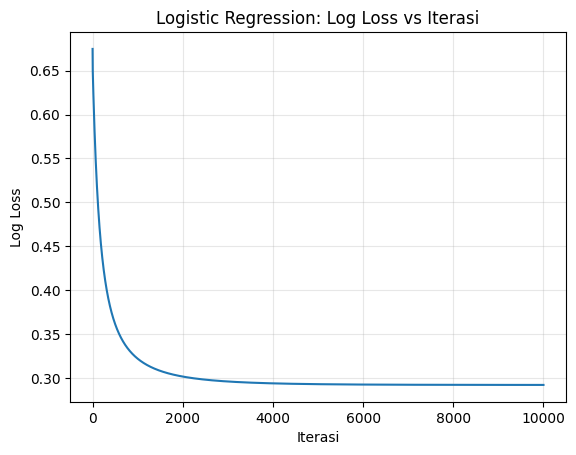

Log loss awal: 0.6748
Log loss akhir: 0.29209


In [35]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
print("X_train:", X_train_email.shape, "| X_test:", X_test_email.shape)
print("y_train:", y_train_email.shape, "| y_test:", y_test_email.shape)
log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print(f"Intercept (b): {log_model.intercept_:.5f}")
print(f"Koefisien m1 (JumlahLink): {log_model.coef_[0]:.5f}")
print(f"Koefisien m2 (KataPromo): {log_model.coef_[1]:.5f}")
print(f"P(Spam) = sigmoid({log_model.intercept_:.5f} + ({log_model.coef_[0]:.5f} × JumlahLink) + ({log_model.coef_[1]:.5f} × KataPromo))")
plt.plot(np.arange(1, len(log_model.loss_history) + 1), log_model.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Logistic Regression: Log Loss vs Iterasi")
plt.grid(alpha=0.3)
plt.show()
print("Log loss awal:", round(log_model.loss_history[0], 5))
print("Log loss akhir:", round(log_model.loss_history[-1], 5))

**Jawaban B2 (analisis):**

Model menghasilkan intercept **-8,39097**, koefisien JumlahLink **0,78040**, dan koefisien KataPromo **0,72696**. Kedua koefisien bernilai positif, sehingga kenaikan salah satu fitur ketika fitur lainnya tetap akan meningkatkan skor linear dan probabilitas spam yang diperkirakan model. Log loss turun dari **0,67480** pada awal pencatatan menjadi **0,29209** setelah 10.000 iterasi, yang menunjukkan model belajar mengurangi kesalahan probabilistik pada data training. Untuk memastikan performa prediksi, hasil tersebut tetap perlu dibandingkan dengan metrik pada data testing.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [36]:
# Jawaban B3
pred_test = log_model.predict(X_test_email, threshold=0.5)
cm = confusion_matrix(y_test_email, pred_test)
print("Confusion matrix (baris aktual [0,1], kolom prediksi [0,1]):")
print(cm)
print("TN={}, FP={}, FN={}, TP={}".format(*cm.ravel()))
print(f"Accuracy : {accuracy_score(y_test_email, pred_test):.4f}")
print(f"Precision: {precision_score(y_test_email, pred_test):.4f}")
print(f"Recall   : {recall_score(y_test_email, pred_test):.4f}")
print(f"F1-score : {f1_score(y_test_email, pred_test):.4f}")

Confusion matrix (baris aktual [0,1], kolom prediksi [0,1]):
[[10  1]
 [ 0  4]]
TN=10, FP=1, FN=0, TP=4
Accuracy : 0.9333
Precision: 0.8000
Recall   : 1.0000
F1-score : 0.8889


**Jawaban B3 (analisis):**

Dari confusion matrix testing `[[10, 1], [0, 4]]`, terdapat **1 false positive (FP)** dan **0 false negative (FN)**. FP berarti satu email bukan spam salah dimasukkan sebagai spam, sehingga pengguna berisiko melewatkan pesan yang sebenarnya penting. FN berarti email spam lolos ke kotak masuk; pada hasil testing ini tidak ada FN. Untuk filter yang berfokus pada keamanan, FN bisa lebih berbahaya karena spam dapat berisi penipuan atau tautan berbahaya, tetapi FP juga merugikan jika menyebabkan email penting terlewat. Pilihan threshold sebaiknya mempertimbangkan kedua risiko tersebut, bukan accuracy saja.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.39097 + (0.78040 × JumlahLink)) / 0.72696


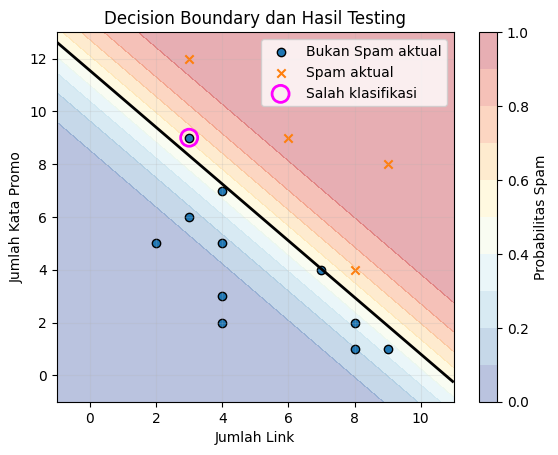

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Aktual,Prediksi
0,3.0,9.0,0,1


In [37]:
# Jawaban B4
b = log_model.intercept_
m1, m2 = log_model.coef_
if abs(m2) < 1e-12:
    print("Decision boundary tidak dapat ditulis sebagai x2 = ... karena koefisien KataPromo mendekati nol.")
else:
    print(f"Decision boundary: KataPromo = -({b:.5f} + ({m1:.5f} × JumlahLink)) / {m2:.5f}")
    x1_grid = np.linspace(X_email[:, 0].min() - 1, X_email[:, 0].max() + 1, 250)
    x2_grid = np.linspace(X_email[:, 1].min() - 1, X_email[:, 1].max() + 1, 250)
    xx1, xx2 = np.meshgrid(x1_grid, x2_grid)
    grid = np.c_[xx1.ravel(), xx2.ravel()]
    probs = log_model.predict_proba(grid)[:, 1].reshape(xx1.shape)
    plt.contourf(xx1, xx2, probs, levels=np.linspace(0, 1, 11), alpha=0.35, cmap="RdYlBu_r")
    plt.colorbar(label="Probabilitas Spam")
    plt.contour(xx1, xx2, probs, levels=[0.5], colors="black", linewidths=2)
    plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1], label="Bukan Spam aktual", marker="o", edgecolors="black")
    plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1], label="Spam aktual", marker="x")
    wrong = pred_test != y_test_email
    plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], s=150, facecolors="none", edgecolors="magenta", linewidths=2, label="Salah klasifikasi")
    plt.xlabel("Jumlah Link")
    plt.ylabel("Jumlah Kata Promo")
    plt.title("Decision Boundary dan Hasil Testing")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()
    errors = pd.DataFrame({"JumlahLink": X_test_email[wrong, 0], "KataPromo": X_test_email[wrong, 1], "Aktual": y_test_email[wrong], "Prediksi": pred_test[wrong]})
    print("Data testing yang salah diklasifikasikan:")
    display(errors if len(errors) else pd.DataFrame(columns=["JumlahLink", "KataPromo", "Aktual", "Prediksi"]))

**Jawaban B4 (analisis):**

Decision boundary adalah garis ketika probabilitas prediksi spam sama dengan 0,5. Pada grafik, warna latar menunjukkan probabilitas model, sedangkan lingkaran magenta menandai titik testing yang salah klasifikasi. Titik tersebut berada di sisi keputusan yang berlawanan dengan label aktualnya. Karena hanya ada dua fitur dan dataset relatif kecil, batas keputusan ini merupakan pendekatan sederhana, bukan aturan universal untuk semua email.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [38]:
# Jawaban B5
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = log_model.predict(X_test_email, threshold=threshold)
    threshold_predictions[threshold] = pred
    cm_t = confusion_matrix(y_test_email, pred)
    tn, fp, fn, tp = cm_t.ravel()
    threshold_rows.append({"Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                           "Precision": precision_score(y_test_email, pred), "Recall": recall_score(y_test_email, pred),
                           "Accuracy": accuracy_score(y_test_email, pred)})
display(pd.DataFrame(threshold_rows).round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy
0,0.3,6,5,0,4,0.4444,1.00,0.6667
1,0.5,10,1,0,4,0.8000,1.00,0.9333
2,0.7,11,0,1,3,1.0000,0.75,0.9333


**Jawaban B5 (analisis):**

Pada hasil pengujian ini, threshold 0,3 dan 0,5 sama-sama menghasilkan recall 1,00, tetapi threshold 0,3 menghasilkan lima false positive dan precision 0,4444. Threshold 0,5 mempertahankan recall 1,00 dengan hanya satu false positive dan precision 0,8000, sehingga menjadi pilihan yang lebih seimbang untuk dataset ini. Threshold 0,7 menghasilkan precision 1,00, tetapi recall turun menjadi 0,75 karena satu email spam tidak terdeteksi. Jadi, berdasarkan hasil testing ini, threshold 0,5 dipilih karena mampu mendeteksi seluruh email spam pada data testing dengan jumlah false positive yang lebih rendah daripada threshold 0,3. Hasil ini khusus untuk pembagian data yang digunakan dan belum tentu berlaku untuk dataset lain.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [39]:
# Jawaban B6
chosen_threshold = 0.5  # dipilih dari hasil B5: recall 1.00 dengan FP lebih sedikit daripada threshold 0.3
new_emails = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"], "JumlahLink": [1, 5, 9, 2], "KataPromo": [2, 6, 10, 11]})
new_X = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_prob = log_model.predict_proba(new_X)[:, 1]
new_class = (new_prob >= chosen_threshold).astype(int)
new_emails["ProbabilitasSpam"] = new_prob
new_emails["Threshold"] = chosen_threshold
new_emails["Prediksi"] = np.where(new_class == 1, "Spam", "Bukan Spam")
display(new_emails.round(4))

,Email,JumlahLink,KataPromo,ProbabilitasSpam,Threshold,Prediksi
0,E1,1,2,0.0021,0.5,Bukan Spam
1,E2,5,6,0.4682,0.5,Bukan Spam
2,E3,9,10,0.9973,0.5,Spam
3,E4,2,11,0.7625,0.5,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression digunakan untuk klasifikasi karena keluarannya berupa probabilitas keanggotaan kelas, yang kemudian dipetakan ke label seperti spam atau bukan spam menggunakan threshold. Fungsi sigmoid mengubah skor linear menjadi angka antara 0 dan 1. Probabilitas itu dapat ditafsirkan sebagai estimasi peluang kelas positif menurut model.

**Jawaban C2:** Normal Equation menghitung parameter regresi secara langsung melalui operasi matriks tanpa iterasi optimisasi. Gradient Descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih sesuai untuk dataset besar atau banyak fitur ketika perhitungan matriks langsung mahal, tetapi hasilnya dipengaruhi learning rate dan jumlah iterasi.

**Jawaban C3:** Data testing dipakai untuk mengukur kemampuan model pada data yang tidak digunakan saat pelatihan. Jika evaluasi hanya dilakukan pada data training, hasilnya dapat terlihat terlalu baik. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan pola atau noise data training sehingga performanya menurun pada data baru.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut cocok dengan label aktual dan memberi penalti besar pada prediksi yang sangat yakin tetapi salah.

**Jawaban C5:** Hasil bisa berbeda karena random_state mengubah data mana yang masuk training dan testing. Parameter awal, learning rate, jumlah iterasi, skala fitur, dan detail implementasi juga memengaruhi hasil. Karena itu, perbandingan yang adil harus memakai pembagian data dan prosedur evaluasi yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [40]:
# Jawaban Bonus — scikit-learn hanya digunakan untuk perbandingan
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sk_linear = SklearnLinearRegression().fit(X_train_a, y_train_a)
sk_train_pred = sk_linear.predict(X_train_a)
sk_test_pred = sk_linear.predict(X_test_a)
print("Linear Regression scikit-learn")
print("Intercept:", sk_linear.intercept_)
print("Koefisien:", sk_linear.coef_)
print("Test RMSE:", root_mean_squared_error(y_test_a, sk_test_pred), "| Test R²:", r2_score(y_test_a, sk_test_pred))

# Logistic Regression sklearn menggunakan regularisasi L2 secara default; C besar berarti regularisasi lebih lemah.
sk_log = SklearnLogisticRegression(C=1e6, max_iter=10000, solver="lbfgs")
sk_log.fit(X_train_email, y_train_email)
sk_pred = sk_log.predict(X_test_email)
print("\nLogistic Regression scikit-learn (C=1e6, mendekati tanpa regularisasi)")
print("Intercept:", sk_log.intercept_[0])
print("Koefisien:", sk_log.coef_[0])
print("Accuracy:", accuracy_score(y_test_email, sk_pred))
print("Confusion matrix:\n", confusion_matrix(y_test_email, sk_pred))
print("Model manual — intercept:", log_model.intercept_, "koefisien:", log_model.coef_)
print("Model manual — accuracy:", accuracy_score(y_test_email, log_model.predict(X_test_email)))

Linear Regression scikit-learn
Intercept: 29.774312259483246
Koefisien: [9.01871358]
Test RMSE: 10.143447227286535 | Test R²: 0.8523478648560202

Logistic Regression scikit-learn (C=1e6, mendekati tanpa regularisasi)
Intercept: -8.54074210906063
Koefisien: [0.79358686 0.73969725]
Accuracy: 0.9333333333333333
Confusion matrix:
 [[10  1]
 [ 0  4]]
Model manual — intercept: -8.390967768423192 koefisien: [0.78039889 0.72695935]
Model manual — accuracy: 0.9333333333333333


**Jawaban Bonus (analisis):**

Pada Linear Regression, Normal Equation manual dan scikit-learn umumnya menghasilkan koefisien yang sama atau sangat dekat karena keduanya meminimalkan jumlah kuadrat error pada data training yang sama. Pada Logistic Regression, hasil dapat berbeda karena scikit-learn menerapkan regularisasi L2 secara default dan menggunakan solver optimisasi yang berbeda. Parameter `C` mengatur kebalikan kekuatan regularisasi; `C` yang besar membuat regularisasi lebih lemah, tetapi tidak menjamin semua angka identik karena toleransi konvergensi dan metode optimisasi juga berbeda.